# Spaceship Titanic - Trabalho Prático II
Disciplina: Aprendizado de Máquina - IF Sudeste MG

**Problema:** prever se um passageiro foi transportado para outra dimensão (`Transported` = True/False).
Competição do Kaggle: https://www.kaggle.com/competitions/spaceship-titanic

**Etapas do trabalho:**
1. Carregar os dados e fazer a EDA
2. Criar variáveis novas
3. Tratar valores ausentes (NaN)
4. Tratar variáveis categóricas
5. Eliminar outliers
6. Padronizar os dados
7. Selecionar variáveis (features)
8. Treinar os modelos com otimização de parâmetros e comparar

## 1. Carregar os dados e EDA

In [1]:
# O CatBoost não vem instalado no Colab
%pip install -q catboost streamlit pyngrok joblib

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Pasta com os arquivos do Kaggle: 'data/' (repositório) ou '/content/' (upload feito no Colab)
pasta_dados = 'data/' if os.path.exists('data/train.csv') else '/content/'

df_treino = pd.read_csv(pasta_dados + 'train.csv')
df_teste = pd.read_csv(pasta_dados + 'test.csv')

print('Treino:', df_treino.shape)
print('Teste:', df_teste.shape)
df_treino.head()

Treino: (8693, 14)
Teste: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
# Tipos de cada coluna e quantidade de valores preenchidos
df_treino.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [4]:
# Estatísticas básicas das colunas numéricas
df_treino.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [5]:
# Quantidade de valores ausentes (NaN) por coluna
df_treino.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64


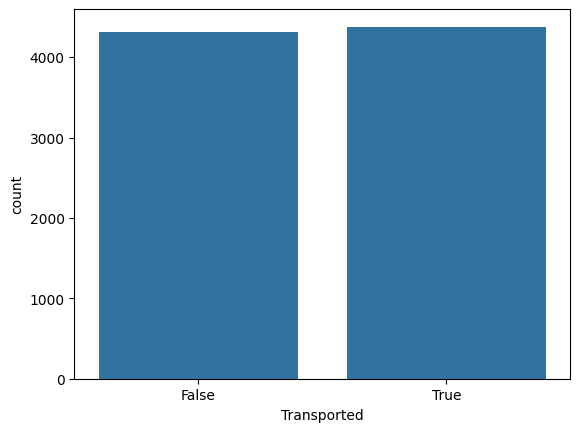

In [6]:
# O alvo está balanceado? (proporção de True e False)
print(df_treino['Transported'].value_counts(normalize=True))
sns.countplot(x='Transported', data=df_treino)
plt.show()

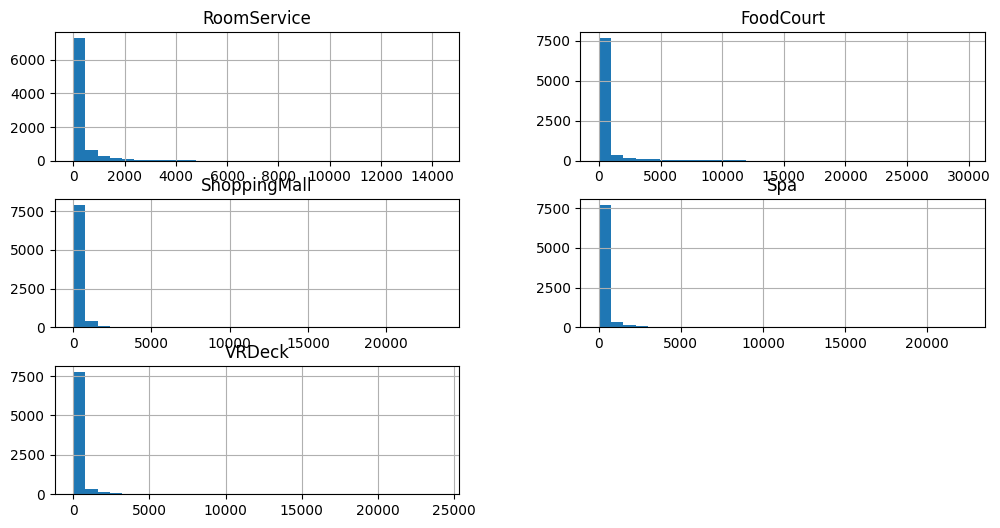

In [7]:
# Distribuição dos gastos: a maioria gasta pouco e poucos passageiros gastam muito
colunas_gastos = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
df_treino[colunas_gastos].hist(bins=30, figsize=(12, 6))
plt.show()

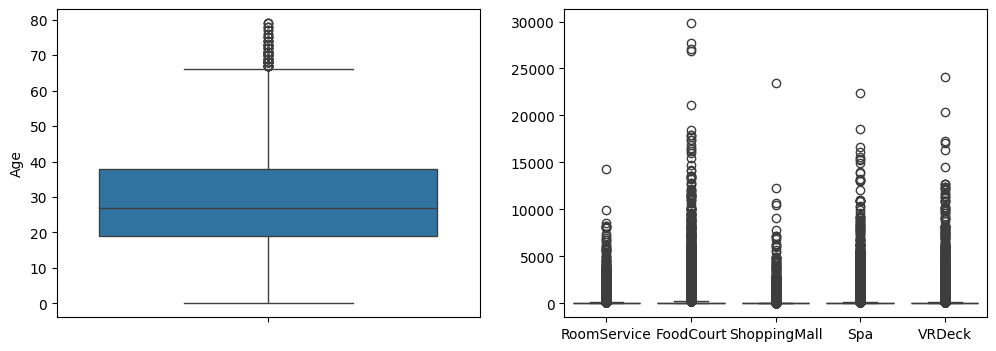

In [8]:
# Boxplot da idade e dos gastos para enxergar os outliers
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df_treino['Age'], ax=eixos[0])
sns.boxplot(data=df_treino[colunas_gastos], ax=eixos[1])
plt.show()

In [9]:
# Taxa de transportados em cada categoria
for coluna in ['CryoSleep', 'HomePlanet', 'Destination', 'VIP']:
    print(df_treino.groupby(coluna)['Transported'].mean().round(3))
    print()

CryoSleep
False    0.329
True     0.818
Name: Transported, dtype: float64

HomePlanet
Earth     0.424
Europa    0.659
Mars      0.523
Name: Transported, dtype: float64

Destination
55 Cancri e      0.610
PSO J318.5-22    0.504
TRAPPIST-1e      0.471
Name: Transported, dtype: float64

VIP
False    0.506
True     0.382
Name: Transported, dtype: float64



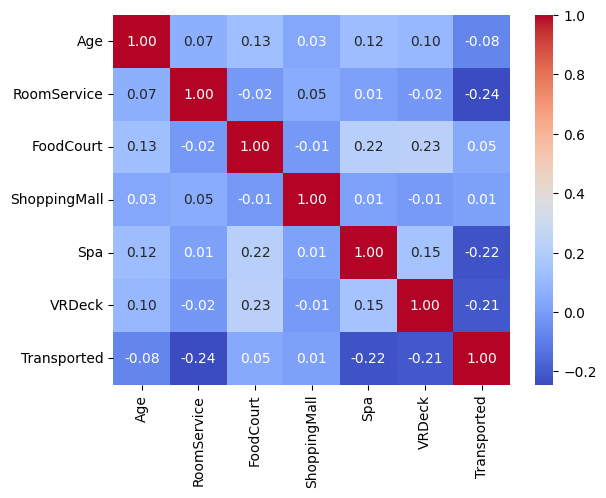

In [10]:
# Correlação entre as colunas numéricas e o alvo
colunas_numericas = ['Age'] + colunas_gastos
correlacao = df_treino[colunas_numericas + ['Transported']].astype(float).corr()
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

In [11]:
# Cabin tem o formato 'deck/número/lado': olhando o deck e a faixa de idade
df_treino['Deck'] = df_treino['Cabin'].str[0]
print(df_treino.groupby('Deck')['Transported'].mean().round(3))
print()
faixa_idade = pd.cut(df_treino['Age'], [-1, 12, 17, 25, 40, 60, 100])
print(df_treino.groupby(faixa_idade, observed=True)['Transported'].mean().round(3))

Deck
A    0.496
B    0.734
C    0.680
D    0.433
E    0.357
F    0.440
G    0.516
T    0.200
Name: Transported, dtype: float64

Age
(-1, 12]     0.700
(12, 17]     0.553
(17, 25]     0.458
(25, 40]     0.480
(40, 60]     0.495
(60, 100]    0.473
Name: Transported, dtype: float64


In [12]:
# Os grupos de viagem (4 primeiros dígitos do PassengerId) se repetem entre treino e teste?
grupos_treino_eda = set(df_treino['PassengerId'].str[:4])
grupos_teste_eda = set(df_teste['PassengerId'].str[:4])
print('Grupos em comum entre treino e teste:', len(grupos_treino_eda & grupos_teste_eda))

Grupos em comum entre treino e teste: 0


**O que a EDA mostrou:**
- O alvo está bem balanceado (cerca de 50% para cada classe).
- Todas as colunas, menos `PassengerId` e `Transported`, têm cerca de 2% de valores ausentes.
- Quem está em sono criogênico (`CryoSleep`) é transportado com muito mais frequência e não gasta nada.
- Os gastos são muito assimétricos, com poucos passageiros gastando valores enormes (outliers).
- Crianças (até 12 anos) são transportadas com mais frequência (70%) e os decks B e C também (cerca de 70%).
- **Treino e teste não têm nenhum grupo de viagem em comum.** Por isso, na validação cruzada vamos manter cada grupo inteiro em uma mesma parte (`GroupKFold`). Assim a validação imita o que acontece com o teste do Kaggle.

## 2. Juntar treino e teste e criar variáveis novas
Juntamos treino e teste em uma única tabela (`df_todos`) para aplicar **exatamente o mesmo tratamento** nos dois.
O alvo `Transported` fica guardado à parte e **não** é usado no tratamento.

In [13]:
qtd_treino = len(df_treino)            # linhas de treino (para separar de novo depois)
alvo = df_treino['Transported'].astype(int)   # 1 = transportado, 0 = não
ids_teste = df_teste['PassengerId']    # necessário para o arquivo de envio

df_todos = pd.concat([df_treino.drop(columns='Transported'), df_teste], ignore_index=True)
df_todos.shape

(12970, 14)

In [14]:
# PassengerId tem o formato 'grupo_número': o grupo indica quem viaja junto
df_todos['Grupo'] = df_todos['PassengerId'].str[:4]
df_todos['TamanhoGrupo'] = df_todos.groupby('Grupo')['PassengerId'].transform('count')
grupos_treino = df_todos['Grupo'].iloc[:qtd_treino]   # usado na validação cruzada

# Cabin tem o formato 'deck/número/lado': guardamos o deck, o número e o lado (P ou S)
df_todos['Deck'] = df_todos['Cabin'].str[0]
df_todos['Lado'] = df_todos['Cabin'].str[-1]
df_todos['NumCabine'] = pd.to_numeric(df_todos['Cabin'].str.split('/').str[1])

# Colunas que não ajudam o modelo (identificadores e texto livre)
df_todos = df_todos.drop(columns=['PassengerId', 'Name', 'Cabin'])   # 'Grupo' ainda será usada nos NaN
df_todos.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,Grupo,TamanhoGrupo,Lado,NumCabine
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,0001,1,P,0.0
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,0002,1,S,0.0
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,0003,2,S,0.0
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,0003,2,S,0.0
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,0004,1,S,1.0


## 3. Tratar valores ausentes (NaN)
Antes de preencher com mediana ou moda, usamos **regras do próprio cenário**. Conferimos cada regra em todas as linhas do `train.csv` e do `test.csv`
juntas (12.970 passageiros, usando só a estrutura dos dados, sem o alvo). Em nenhuma delas apareceu exceção:

| Regra | Exceções |
|---|---|
| Quem está em CryoSleep não gasta nada | 0 |
| Quem gasta algo não está em CryoSleep | 0 |
| Menores de 13 anos não gastam nada | 0 |
| Passageiros do mesmo grupo têm o mesmo planeta e o mesmo lado da cabine | 0 |
| O deck revela o planeta: A, B, C e T são Europa, G é Terra | 0 |
| Quem é da Terra nunca é VIP | 0 |

**Atenção:** o grupo **não** garante o mesmo deck nem o mesmo número de cabine (em cerca de 32% dos grupos eles mudam).
Mesmo assim, quando faltam, usamos o deck e a cabine de um colega de grupo como estimativa. Testamos nos passageiros que têm essas informações:
essa estimativa acerta o deck 72% das vezes, contra 26% se usássemos o deck mais comum.

Depois das regras, o que sobrar é preenchido com a **mediana** (números) ou a **moda** (categorias).

In [15]:
# Regra do grupo: quem viaja junto divide planeta e lado (sempre) e, na maioria das vezes, deck e número da cabine (estimativa)
for coluna in ['HomePlanet', 'Lado', 'Deck', 'NumCabine']:
    df_todos[coluna] = df_todos[coluna].fillna(df_todos.groupby('Grupo')[coluna].transform('first'))

# Regra do deck: A, B, C e T só têm passageiros de Europa; G só tem da Terra
df_todos.loc[df_todos['HomePlanet'].isna() & df_todos['Deck'].isin(['A', 'B', 'C', 'T']), 'HomePlanet'] = 'Europa'
df_todos.loc[df_todos['HomePlanet'].isna() & (df_todos['Deck'] == 'G'), 'HomePlanet'] = 'Earth'

# Regra do VIP: ninguém da Terra é VIP
df_todos.loc[df_todos['HomePlanet'] == 'Earth', 'VIP'] = False

In [16]:
# Regras do CryoSleep: quem gasta não está em CryoSleep; sem nenhum gasto, o mais provável é que esteja
gasto_conhecido = df_todos[colunas_gastos].sum(axis=1)
df_todos.loc[df_todos['CryoSleep'].isna() & (gasto_conhecido > 0), 'CryoSleep'] = False
df_todos.loc[df_todos['CryoSleep'].isna() & (gasto_conhecido == 0), 'CryoSleep'] = True

# Regras do gasto: quem está em CryoSleep ou tem menos de 13 anos não gasta nada
sem_gasto = (df_todos['CryoSleep'] == True) | (df_todos['Age'] < 13)
for coluna in colunas_gastos:
    df_todos.loc[sem_gasto, coluna] = 0

In [17]:
# Colunas numéricas: preencher com a mediana
colunas_numericas = ['Age', 'NumCabine'] + colunas_gastos
for coluna in colunas_numericas:
    df_todos[coluna] = df_todos[coluna].fillna(df_todos[coluna].median())

# Colunas categóricas: preencher com a moda
colunas_categoricas = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Lado']
for coluna in colunas_categoricas:
    df_todos[coluna] = df_todos[coluna].fillna(df_todos[coluna].mode()[0])

# A coluna Grupo já cumpriu seu papel
df_todos = df_todos.drop(columns='Grupo')

# Conferir: não pode sobrar nenhum NaN
print('NaN restantes:', df_todos.isnull().sum().sum())

NaN restantes: 0


In [18]:
# Variáveis novas: gasto total, gasto com luxo e gasto básico
# Na EDA, RoomService, Spa e VRDeck têm correlação negativa com o alvo; FoodCourt e ShoppingMall, positiva
df_todos['GastoTotal'] = df_todos[colunas_gastos].sum(axis=1)
df_todos['GastoLuxo'] = df_todos['RoomService'] + df_todos['Spa'] + df_todos['VRDeck']
df_todos['GastoBasico'] = df_todos['FoodCourt'] + df_todos['ShoppingMall']

## 4. Tratar variáveis categóricas
- `CryoSleep` e `VIP` são True/False, então viram 1/0.
- `HomePlanet`, `Destination`, `Deck` e `Lado` viram colunas 0/1 (one-hot encoding), uma para cada categoria.

In [19]:
df_todos['CryoSleep'] = df_todos['CryoSleep'].astype(int)
df_todos['VIP'] = df_todos['VIP'].astype(int)

df_todos = pd.get_dummies(df_todos, columns=['HomePlanet', 'Destination', 'Deck', 'Lado'], dtype=int)
df_todos.head()

,CryoSleep,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TamanhoGrupo,NumCabine,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Lado_P,Lado_S
0,0,39.0,0,0.0,0.0,0.0,0.0,0.0,1,0.0,...,0,1,0,0,0,0,0,0,1,0
1,0,24.0,0,109.0,9.0,25.0,549.0,44.0,1,0.0,...,0,0,0,0,0,1,0,0,0,1
2,0,58.0,1,43.0,3576.0,0.0,6715.0,49.0,2,0.0,...,1,0,0,0,0,0,0,0,0,1
3,0,33.0,0,0.0,1283.0,371.0,3329.0,193.0,2,0.0,...,1,0,0,0,0,0,0,0,0,1
4,0,16.0,0,303.0,70.0,151.0,565.0,2.0,1,1.0,...,0,0,0,0,0,1,0,0,0,1


In [20]:
# Separar de novo em treino e teste
X_treino = df_todos.iloc[:qtd_treino]
X_teste = df_todos.iloc[qtd_treino:]
y_treino = alvo
print('X_treino:', X_treino.shape, '| X_teste:', X_teste.shape)

X_treino: (8693, 29) | X_teste: (4277, 29)


## 5. Eliminar outliers (somente no treino)
Usamos o método do **IQR** no `GastoTotal`: é outlier quem gasta mais que `Q3 + 8 x IQR`.

Por que o fator 8 e não o 1,5 ou 3 que são mais comuns? Nesses dados muitos passageiros gastam zero, então o IQR é pequeno e fatores menores
removem muita gente que não é erro, e sim passageiro que gasta bastante. Testando com validação cruzada, o fator 3 removia 6% das linhas e
**piorava** a acurácia em cerca de 1,2 ponto. Com o fator 8 removemos só os casos realmente extremos (cerca de 1%).

Os dados de teste **não** perdem linhas, pois o Kaggle espera uma previsão para cada passageiro.

In [21]:
q1 = X_treino['GastoTotal'].quantile(0.25)
q3 = X_treino['GastoTotal'].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 8 * iqr
print('Limite de gasto total:', limite_superior)

sem_outlier = X_treino['GastoTotal'] <= limite_superior
print('Linhas removidas:', (~sem_outlier).sum())

X_treino = X_treino[sem_outlier]
y_treino = y_treino[sem_outlier]
grupos_treino = grupos_treino[sem_outlier].reset_index(drop=True)
print('Treino depois da limpeza:', X_treino.shape)

Limite de gasto total: 12969.0
Linhas removidas: 99
Treino depois da limpeza: (8594, 29)


## 6. Padronizar os dados
O `StandardScaler` deixa cada coluna com média 0 e desvio padrão 1.
É importante para Regressão Logística, KNN e SVM, que são sensíveis à escala. Árvores não precisam, mas não são prejudicadas.
O ajuste (`fit`) é feito **só no treino**, e o teste recebe a mesma transformação.

In [22]:
from sklearn.preprocessing import StandardScaler

padronizador = StandardScaler()
colunas = X_treino.columns

X_treino = pd.DataFrame(padronizador.fit_transform(X_treino), columns=colunas)
X_teste = pd.DataFrame(padronizador.transform(X_teste), columns=colunas)
y_treino = y_treino.reset_index(drop=True)

## 7. Selecionar variáveis (features)
Treinamos uma Random Forest só para medir a **importância** de cada coluna.
Mantemos as colunas com importância de pelo menos 0,2%, ou seja, só tiramos as colunas quase inúteis.
Com um corte maior (2%) a acurácia caiu cerca de 1,5 ponto, porque jogávamos informação útil fora.

**CatBoost:** usa todas as colunas. Na validação cruzada ele fica igual (0,813) com ou sem as 3 colunas removidas, e cortes maiores pioram (0,5% → 0,810; 2% → 0,796).

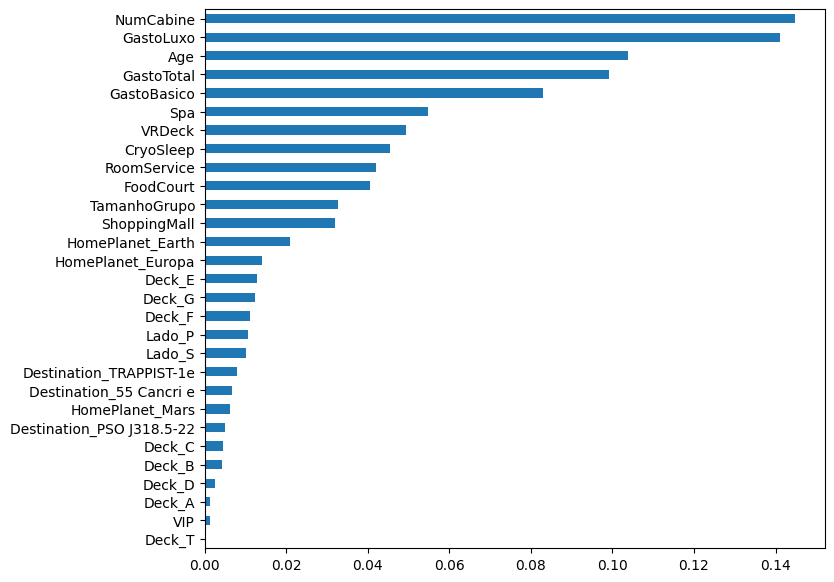

In [23]:
from sklearn.ensemble import RandomForestClassifier

floresta = RandomForestClassifier(n_estimators=100, random_state=42)
floresta.fit(X_treino, y_treino)

importancias = pd.Series(floresta.feature_importances_, index=colunas).sort_values()
importancias.plot(kind='barh', figsize=(8, 7))
plt.show()

In [24]:
colunas_escolhidas = importancias[importancias >= 0.002].index

# Guardamos a versão com todas as colunas: o CatBoost vai usá-la (empata na validação cruzada e já lida bem com colunas pouco úteis)
X_treino_completo = X_treino.copy()
X_teste_completo = X_teste.copy()

X_treino = X_treino[colunas_escolhidas]
X_teste = X_teste[colunas_escolhidas]
print('Variáveis mantidas:', len(colunas_escolhidas), 'de', len(colunas))
list(colunas_escolhidas)

Variáveis mantidas: 26 de 29


['Deck_D',
 'Deck_B',
 'Deck_C',
 'Destination_PSO J318.5-22',
 'HomePlanet_Mars',
 'Destination_55 Cancri e',
 'Destination_TRAPPIST-1e',
 'Lado_S',
 'Lado_P',
 'Deck_F',
 'Deck_G',
 'Deck_E',
 'HomePlanet_Europa',
 'HomePlanet_Earth',
 'ShoppingMall',
 'TamanhoGrupo',
 'FoodCourt',
 'RoomService',
 'CryoSleep',
 'VRDeck',
 'Spa',
 'GastoBasico',
 'GastoTotal',
 'Age',
 'GastoLuxo',
 'NumCabine']

## 8. Modelos, otimização de parâmetros e comparação
Para cada modelo usamos o `GridSearchCV`: ele testa algumas combinações de parâmetros com validação cruzada
de 5 partes e escolhe a melhor pela acurácia. As partes são feitas com `GroupKFold`, que mantém cada grupo de viagem inteiro em uma só parte.

**Algoritmo extra (item 4 do enunciado): CatBoost.** Ele treina várias árvores **em sequência**:
cada árvore nova tenta corrigir os erros das anteriores (*gradient boosting*).
A Random Forest, ao contrário, treina árvores independentes e faz a média (*bagging*).
O CatBoost tem duas diferenças para outros métodos de boosting: usa **árvores simétricas** (todos os nós de um mesmo nível
fazem a mesma pergunta), o que funciona como uma regularização, e o *ordered boosting*, que reduz o sobreajuste em bases pequenas.

Referência: Prokhorenkova, L. et al. *CatBoost: unbiased boosting with categorical features*. NeurIPS 2018. https://arxiv.org/abs/1706.09516

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier

# Cada modelo vem com os parâmetros que serão testados na otimização
modelos = {
    'Regressao Logistica': (LogisticRegression(max_iter=1000), {'C': [0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': [5, 11, 21]}),
    'Naive Bayes': (GaussianNB(), {'var_smoothing': [1e-9, 1e-6, 1e-3]}),
    'SVM': (SVC(), {'C': [0.5, 1, 5]}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42), {'max_depth': [3, 5, 7, 10]}),
    'Random Forest': (RandomForestClassifier(random_state=42), {'n_estimators': [100, 300], 'max_depth': [5, 8, 12]}),
    'CatBoost': (CatBoostClassifier(random_state=0, verbose=0, allow_writing_files=False), {'depth': [6, 8]}),
}

In [26]:
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

os.makedirs('submissoes', exist_ok=True)   # pasta com um arquivo de envio por modelo
resultados = []

for nome, (modelo, parametros) in modelos.items():
    # o CatBoost usa todas as colunas; os outros modelos usam só as selecionadas
    if nome == 'CatBoost':
        X_modelo, X_envio = X_treino_completo, X_teste_completo
    else:
        X_modelo, X_envio = X_treino, X_teste

    # 1) otimização de parâmetros com validação cruzada
    busca = GridSearchCV(modelo, parametros, cv=GroupKFold(5), scoring='accuracy')
    busca.fit(X_modelo, y_treino, groups=grupos_treino)
    melhor_modelo = busca.best_estimator_

    # 2) métricas no conjunto de treino (as pedidas no enunciado)
    previsao_treino = melhor_modelo.predict(X_modelo)
    vn, fp, fn, vp = confusion_matrix(y_treino, previsao_treino).ravel()

    resultados.append({
        'Modelo': nome,
        'Acuracia treino': accuracy_score(y_treino, previsao_treino),
        'Acuracia validacao cruzada': busca.best_score_,
        'Precisao': precision_score(y_treino, previsao_treino),
        'Especificidade': vn / (vn + fp),
        'Recall': recall_score(y_treino, previsao_treino),
        'F1-Score': f1_score(y_treino, previsao_treino),
        'Melhores parametros': busca.best_params_,
    })

    # 3) arquivo para enviar ao Kaggle
    previsao_teste = melhor_modelo.predict(X_envio).astype(bool)
    envio = pd.DataFrame({'PassengerId': ids_teste, 'Transported': previsao_teste})
    envio.to_csv('submissoes/' + nome.replace(' ', '_') + '.csv', index=False)
    print('Pronto:', nome)

Pronto: Regressao Logistica


Pronto: KNN
Pronto: Naive Bayes


Pronto: SVM


Pronto: Decision Tree


Pronto: Random Forest


Pronto: CatBoost


### Quadro comparativo
A coluna **Acurácia validação cruzada** é a mais confiável para comparar os modelos, pois mede dados que o modelo não viu no treino.
A coluna **Kaggle** é a pontuação pública de cada arquivo da pasta `submissoes/`, enviado ao Kaggle (conjunto de teste).

In [27]:
tabela = pd.DataFrame(resultados).set_index('Modelo')

# Pontuação pública obtida no Kaggle ao enviar o arquivo de cada modelo
tabela['Kaggle'] = pd.Series({'Regressao Logistica': 0.79261, 'KNN': 0.78816, 'Naive Bayes': 0.76548, 'SVM': 0.80336,
                              'Decision Tree': 0.79611, 'Random Forest': 0.80336, 'CatBoost': 0.80804})
tabela.to_csv('quadro_comparativo.csv')
tabela.round(4)

,Acuracia treino,Acuracia validacao cruzada,Precisao,Especificidade,Recall,F1-Score,Melhores parametros,Kaggle
Modelo,,,,,,,,
Regressao Logistica,0.7880,0.7862,0.7800,0.7661,0.8094,0.7944,{'C': 0.1},0.7926
KNN,0.8291,0.7857,0.8430,0.8448,0.8138,0.8281,{'n_neighbors': 11},0.7882
Naive Bayes,0.7549,0.7535,0.7003,0.6047,0.9016,0.7883,{'var_smoothing': 1e-09},0.7655
SVM,0.8184,0.8022,0.8181,0.8122,0.8243,0.8212,{'C': 1},0.8034
Decision Tree,0.8013,0.7882,0.7828,0.7611,0.8404,0.8106,{'max_depth': 5},0.7961
Random Forest,0.9095,0.8044,0.9104,0.9081,0.9108,0.9106,"{'max_depth': 12, 'n_estimators': 100}",0.8034
CatBoost,0.8839,0.8134,0.8802,0.8756,0.8919,0.8860,{'depth': 6},0.8080


## 9. Exportar os modelos (.pkl)
Salvamos com `joblib` os 4 modelos usados no app, a lista de colunas do treino e o padronizador. Os `.pkl` ficam na pasta `modelos/`.

In [ ]:
import joblib

# Pasta que o app lê
os.makedirs('modelos', exist_ok=True)

# O loop do GridSearchCV sobrescreve `melhor_modelo` a cada volta e guarda só os resultados em `tabela`.
# Então refazemos o ajuste de cada modelo com os melhores parâmetros (o resultado é o mesmo do best_estimator_).
# O CatBoost usa as 29 colunas (X_treino_completo); os outros usam as 26 selecionadas (X_treino).
modelos_para_app = {
    'CatBoost': ('modelo_catboost.pkl', X_treino_completo),
    'Random Forest': ('modelo_random_forest.pkl', X_treino),
    'KNN': ('modelo_knn.pkl', X_treino),
    'Regressao Logistica': ('modelo_regressao_logistica.pkl', X_treino),
}

for nome, (arquivo, dados_treino) in modelos_para_app.items():
    modelo = modelos[nome][0]                                     # modelo ainda sem treinar
    modelo.set_params(**tabela.loc[nome, 'Melhores parametros'])  # aplica os melhores parâmetros
    modelo.fit(dados_treino, y_treino)
    joblib.dump(modelo, 'modelos/' + arquivo)
    print('Salvo: modelos/' + arquivo, '| colunas usadas:', dados_treino.shape[1])

# Lista com as 29 colunas, na ordem do treino (o app monta a linha do passageiro com ela)
joblib.dump(list(colunas), 'modelos/colunas_treino.pkl')
# StandardScaler ajustado no treino (o app padroniza o passageiro do mesmo jeito)
joblib.dump(padronizador, 'modelos/padronizador.pkl')
print('Salvo: modelos/colunas_treino.pkl e modelos/padronizador.pkl')

## 10. Data App com Streamlit
O app (`app_spaceship.py`) carrega os `.pkl` da pasta `modelos/`, recebe os dados de um passageiro e prevê ao clicar no botão. O `%%writefile` cria o arquivo no Colab.

In [ ]:
# Tema do app (escuro e roxo): o Streamlit lê este arquivo ao iniciar
import os
os.makedirs('.streamlit', exist_ok=True)
open('.streamlit/config.toml', 'w').write('# Tema do app: escuro e roxo (o Streamlit usa essas cores nos campos, botões e abas)\n[theme]\nbase = "dark"\nprimaryColor = "#9d4edd"\nbackgroundColor = "#0b0d24"\nsecondaryBackgroundColor = "#151a45"\ntextColor = "#ffffff"\n\n[client]\n# esconde o botão "Deploy" do topo\ntoolbarMode = "minimal"\n')

In [ ]:
%%writefile app_spaceship.py
# ============================================================
# App Streamlit - Spaceship Titanic
# Carrega os modelos treinados (.pkl), recebe os dados de um passageiro
# e mostra se ele foi transportado para outra dimensão.
# ============================================================
import os
import joblib            # lê os arquivos .pkl (modelos, colunas e padronizador)
import altair as alt     # usado no gráfico da aba "Gráficos"
import pandas as pd
import streamlit as st

# Título e ícone da aba do navegador. Sempre deve ser o primeiro comando do Streamlit.
st.set_page_config(page_title='Spaceship Titanic', page_icon=':material/rocket_launch:', layout='centered')

# Pasta onde estão os .pkl: a pasta "modelos" ao lado deste arquivo (funciona no Colab e no computador)
PASTA_MODELOS = os.environ.get('PASTA_MODELOS', os.path.join(os.path.dirname(os.path.abspath(__file__)), 'modelos'))

# Nome da coluna no dataset -> nome que aparece na tela
COLUNAS_GASTOS = {'RoomService': 'Serviço de quarto', 'FoodCourt': 'Restaurante', 'ShoppingMall': 'Shopping',
          'Spa': 'Spa', 'VRDeck': 'Realidade virtual'}

# Nome que aparece no seletor -> arquivo .pkl do modelo treinado
ARQUIVOS_MODELOS = {
    'CatBoost (melhor)': 'modelo_catboost.pkl',
    'Random Forest': 'modelo_random_forest.pkl',
    'KNN': 'modelo_knn.pkl',
    'Regressão Logística': 'modelo_regressao_logistica.pkl',
}

# ---------------- Visual (CSS) ----------------
# O Streamlit permite injetar CSS. Aqui deixamos o app com o estilo da NASA
# (cantos retos, títulos em maiúsculas, faixa no topo) nas cores roxas.
# Nada daqui interfere na previsão, é só aparência.
st.markdown("""
<style>
.stApp { background: radial-gradient(circle at top, #1b1f4b 0%, #0b0d24 60%); }
html, body, [class*="css"], .stApp { font-family: "Helvetica Neue", Helvetica, Arial, sans-serif; }
h1, h2, h3, p, label, span, div { color: #fff; }
header[data-testid="stHeader"] { background: transparent; }
.topo { border-top: 6px solid #c77dff; padding: 1.6rem 0 1.2rem; margin-bottom: 0.5rem; border-bottom: 1px solid #3a3f7a; }
.topo small { color: #c77dff; letter-spacing: 0.25em; font-weight: 700; font-size: 0.8rem; }
.topo h1 { background: linear-gradient(90deg, #7c9cff, #c77dff); -webkit-background-clip: text; -webkit-text-fill-color: transparent; font-size: 3.2rem; line-height: 1; margin: 0.4rem 0 0.6rem; text-transform: uppercase; letter-spacing: 0.04em; font-weight: 800; }
.topo p { color: #b8b8b8; margin: 0; font-size: 1.05rem; }
/* Cartão de resultado: .sim (roxo) quando transportado, .nao (vinho) quando não */
.resultado { border-radius: 0; padding: 1.4rem 1.6rem; margin: 1.2rem 0; font-size: 1.8rem; font-weight: 800;
             text-transform: uppercase; letter-spacing: 0.06em; border-left: 10px solid; }
.sim { background: linear-gradient(90deg, #5a3fd0, #9d4edd); border-color: #fff; }
.nao { background: linear-gradient(90deg, #7a2740, #c0485f); border-color: #fff; }
div[data-testid="stMetric"] { background: rgba(255,255,255,0.05); border: 1px solid #3a3f7a; border-radius: 0; padding: 1rem 1.2rem; }
div[data-testid="stMetricLabel"] p { text-transform: uppercase; letter-spacing: 0.1em; font-size: 0.75rem; color: #b8b8b8; }
div[data-testid="stMetricValue"] { font-weight: 800; }
section[data-testid="stSidebar"] { background: #0f1230; border-right: 1px solid #3a3f7a; }
section[data-testid="stSidebar"] h2 { text-transform: uppercase; letter-spacing: 0.08em; font-size: 1.1rem; }
button[data-baseweb="tab"] { text-transform: uppercase; letter-spacing: 0.08em; font-weight: 700; }
div[data-baseweb="tab-highlight"] { background-color: #c77dff; }
div[data-baseweb="select"] > div, input { border-radius: 0 !important; }
.stButton > button { border-radius: 0; font-weight: 800; text-transform: uppercase; letter-spacing: 0.12em; padding: 0.8rem; border: none; }
.stButton > button[kind="primary"] { background: linear-gradient(90deg, #5a3fd0, #9d4edd); color: #fff; }
.stButton > button[kind="primary"]:hover { filter: brightness(1.15); }
</style>
<div class="topo"><small>MISSÃO DE ANÁLISE DE DADOS</small><h1>Spaceship Titanic</h1><p>Preencha os dados do passageiro e veja se ele foi transportado para outra dimensão.</p></div>
""", unsafe_allow_html=True)


# ---------------- Carregar arquivos ----------------
@st.cache_resource   # lê o .pkl do disco uma vez só e guarda na memória (o app fica mais rápido)
def carregar(arquivo):
    return joblib.load(os.path.join(PASTA_MODELOS, arquivo))


# ---------------- Preparar os dados do passageiro ----------------
def montar_linha(passageiro, colunas_treino):
    """Transforma o que o usuário digitou numa linha igual às do treino.

    O modelo só entende a tabela no formato em que foi treinado. Por isso repetimos
    aqui o mesmo tratamento do notebook de treino, para um único passageiro.
    """
    # Regra descoberta na análise: quem está em CryoSleep ou tem menos de 13 anos nunca gasta
    sem_gasto = passageiro['sono_criogenico'] or passageiro['idade'] < 13
    gastos = {nome_gasto: 0 if sem_gasto else passageiro[nome_gasto] for nome_gasto in COLUNAS_GASTOS}

    linha_passageiro = {
        'CryoSleep': int(passageiro['sono_criogenico']), 'Age': passageiro['idade'], 'VIP': int(passageiro['passageiro_vip']), **gastos,
        'TamanhoGrupo': passageiro['tamanho_grupo'], 'NumCabine': passageiro['numero_cabine'],
        # Variáveis criadas no treino: soma de todos os gastos, gastos de luxo e gastos básicos
        'GastoTotal': sum(gastos.values()),
        'GastoLuxo': gastos['RoomService'] + gastos['Spa'] + gastos['VRDeck'],
        'GastoBasico': gastos['FoodCourt'] + gastos['ShoppingMall'],
    }
    # One-hot encoding: no treino cada categoria virou uma coluna 0/1 (ex.: HomePlanet_Europa).
    # Aqui marcamos 1 só na categoria escolhida; as outras colunas ficam 0 no reindex abaixo.
    for prefixo, valor in [('HomePlanet', passageiro['planeta']), ('Destination', passageiro['destino']),
                           ('Deck', passageiro['deck']), ('Lado', passageiro['lado'])]:
        linha_passageiro[f'{prefixo}_{valor}'] = 1
    # reindex coloca as colunas na MESMA ORDEM do treino (lista salva em colunas_treino.pkl)
    return pd.DataFrame([linha_passageiro]).reindex(columns=colunas_treino, fill_value=0)


# ---------------- Barra lateral (st.sidebar) ----------------
with st.sidebar:
    st.header(':material/tune: Modelo')
    nome_modelo = st.selectbox('Escolha o modelo', list(ARQUIVOS_MODELOS))
    st.caption('O CatBoost teve a melhor acurácia na validação cruzada (81,3%).')

# ---------------- Abas (st.tabs) ----------------
aba_prever, aba_graficos, aba_sobre = st.tabs([':material/query_stats: Prever', ':material/bar_chart: Gráficos', ':material/info: Como funciona'])

# ===== Aba 1: formulário + previsão =====
with aba_prever:
    # Dados principais do passageiro
    coluna_idade, coluna_planeta, coluna_destino = st.columns(3)
    idade = coluna_idade.number_input('Idade', 0, 90, 28)
    planeta = coluna_planeta.selectbox('Planeta de origem', ['Earth', 'Europa', 'Mars'])
    destino = coluna_destino.selectbox('Destino', ['TRAPPIST-1e', '55 Cancri e', 'PSO J318.5-22'])

    coluna_sono, coluna_vip = st.columns(2)
    sono_criogenico = coluna_sono.toggle('Em sono criogênico')
    passageiro_vip = coluna_vip.toggle('É VIP')

    # Os campos de gasto ficam desativados quando a regra "não gasta" se aplica
    sem_gasto = sono_criogenico or idade < 13
    st.markdown('**Gastos a bordo**')
    if sem_gasto:
        st.caption('Quem está em sono criogênico ou tem menos de 13 anos não gasta nada.')
    gastos = {}
    for coluna_da_tela, (nome_coluna, rotulo_gasto) in zip(st.columns(5), COLUNAS_GASTOS.items()):
        gastos[nome_coluna] = coluna_da_tela.number_input(rotulo_gasto, 0, 30000, 0, step=100, disabled=sem_gasto)

    # Campos que o modelo usa, mas que o usuário comum não precisa mexer (têm valor padrão)
    with st.expander('Detalhes da cabine e do grupo (opcional)'):
        coluna_deck, coluna_lado, coluna_cabine, coluna_grupo = st.columns(4)
        deck = coluna_deck.selectbox('Deck', list('ABCDEFGT'), index=6)
        lado = coluna_lado.selectbox('Lado', ['P', 'S'])
        numero_cabine = coluna_cabine.number_input('Nº da cabine', 0, 2000, 300)
        tamanho_grupo = coluna_grupo.number_input('Pessoas no grupo', 1, 8, 1)

    # A previsão só roda quando o botão é clicado
    if st.button('Prever', icon=':material/rocket_launch:', type='primary', width='stretch'):
        # 1) Carregar do disco o modelo escolhido, a lista de colunas e o padronizador
        try:
            modelo = carregar(ARQUIVOS_MODELOS[nome_modelo])
            colunas_treino = carregar('colunas_treino.pkl')
            padronizador = carregar('padronizador.pkl')
        except FileNotFoundError as erro_arquivo:
            st.error(f'Arquivo não encontrado: {erro_arquivo.filename}. Faça o upload dos .pkl no Colab.')
            st.stop()

        # 2) Montar a linha do passageiro no formato do treino
        passageiro = dict(idade=idade, planeta=planeta, destino=destino, sono_criogenico=sono_criogenico, passageiro_vip=passageiro_vip, deck=deck,
                          lado=lado, numero_cabine=numero_cabine, tamanho_grupo=tamanho_grupo, **gastos)
        linha_passageiro = montar_linha(passageiro, colunas_treino)

        # 3) Padronizar com o MESMO StandardScaler do treino (os modelos foram treinados com dados padronizados)
        dados_padronizados = pd.DataFrame(padronizador.transform(linha_passageiro), columns=colunas_treino)

        # 4) Cada modelo usa as colunas com que foi treinado: o CatBoost usa todas (29),
        #    os outros usam só as selecionadas pela importância (26)
        colunas_modelo = list(modelo.feature_names_in_ if hasattr(modelo, 'feature_names_in_') else modelo.feature_names_)

        # 5) predict_proba devolve [chance de NÃO ser transportado, chance de SER transportado]; pegamos a segunda
        probabilidade = float(modelo.predict_proba(dados_padronizados[colunas_modelo])[0][1])

        # 6) Mostrar o resultado: 50% ou mais = transportado
        if probabilidade >= 0.5:
            st.markdown('<div class="resultado sim">Foi transportado!</div>', unsafe_allow_html=True)
        else:
            st.markdown('<div class="resultado nao">Não foi transportado</div>', unsafe_allow_html=True)
        # Totalizadores (st.metric)
        metrica_chance, metrica_gasto, metrica_modelo = st.columns(3)
        metrica_chance.metric('Chance de ser transportado', f'{probabilidade:.0%}')
        metrica_gasto.metric('Gasto total', f'{0 if sem_gasto else sum(gastos.values()):,}')
        metrica_modelo.metric('Modelo', nome_modelo.split(' (')[0])

# ===== Aba 2: gráficos =====
# Taxas de transporte observadas no treino (8.693 passageiros), calculadas na análise do relatório.
# São números fixos: assim o app não precisa do train.csv.
TAXAS_TRANSPORTE = {
    'Sono criogênico': {'Em CryoSleep': 81.8, 'Acordado': 32.9},
    'Planeta de origem': {'Europa': 65.9, 'Marte': 52.3, 'Terra': 42.4},
    'Idade': {'0 anos': 80.9, '1 a 12': 66.9, '13 a 17': 55.3, '18 a 25': 45.8,
              '26 a 40': 48.0, '41 a 60': 49.5, 'Mais de 60': 47.3},
    'Deck da cabine': {'B': 73.4, 'C': 68.0, 'G': 51.6, 'F': 44.0, 'D': 43.3, 'E': 35.7},
    'Tamanho do grupo': {'Sozinho': 45.2, '2 pessoas': 53.8, '3 pessoas': 59.3, '4 pessoas': 64.1},
}

with aba_graficos:
    fator_escolhido = st.selectbox('Ver a chance de ser transportado por:', list(TAXAS_TRANSPORTE))
    dados_grafico = pd.DataFrame({'Grupo': list(TAXAS_TRANSPORTE[fator_escolhido]), 'Transportados (%)': list(TAXAS_TRANSPORTE[fator_escolhido].values())})
    # sort=None mantém as barras na ordem em que escrevemos (senão o Altair ordena por letra)
    grafico_barras = alt.Chart(dados_grafico).mark_bar(color='#9d4edd').encode(
        x=alt.X('Grupo', sort=None, axis=alt.Axis(labelAngle=0, title=None)),
        y=alt.Y('Transportados (%)', scale=alt.Scale(domain=[0, 100])),
        tooltip=['Grupo', 'Transportados (%)'])
    st.altair_chart(grafico_barras, width='stretch')
    st.caption('Taxa geral de transportados no treino: 50,4%. São taxas observadas e mostram associação, não causa.')

# ===== Aba 3: explicação =====
with aba_sobre:
    st.markdown("""
Este app usa modelos de Machine Learning treinados com o dataset **Spaceship Titanic** (Kaggle).

1. Você preenche os dados de um passageiro.
2. O app monta as mesmas variáveis usadas no treino (gasto total, gasto de luxo e básico, etc.).
3. O modelo escolhido calcula a **chance de o passageiro ter sido transportado**.

**O que os dados mostram:** quem estava em sono criogênico foi transportado em 82% dos casos
(contra 33% de quem estava acordado), e passageiros de Europa tiveram mais chance (66%) que os da Terra (42%).
""")


## 11. Deploy com Ngrok
Crie uma conta em dashboard.ngrok.com, copie o *Your Authtoken* e cole abaixo. O link público aparece na saída da célula.

In [ ]:
from pyngrok import ngrok

NGROK_TOKEN = 'COLE_SEU_TOKEN_AQUI'
ngrok.set_auth_token(NGROK_TOKEN)

In [ ]:
!pkill -f streamlit
!nohup streamlit run app_spaceship.py --server.port 8501 --server.headless true > logs.txt 2>&1 &

import time
time.sleep(8)
ngrok.kill()
url = ngrok.connect(8501)
print('Link público do app:', url.public_url)

Se o link der erro ou a página ficar em branco, veja os logs:

In [ ]:
!cat logs.txt